# ENSO and Colorado water supply

Companion to `snow_pack`, `co_groundwater` and `co_streamflow`. Loads NOAA CPC's ENSO indices, classifies El Niño / La Niña events, maps them onto Colorado **water years**, and (if `data/co_streamflow_annual.csv` exists from the streamflow notebook) tests whether ENSO state relates to annual streamflow volume.

**Indices.** CPC is moving from the classic **ONI** (departure from a 30-year Niño-3.4 climatology) to the **Relative ONI (RONI)** (Niño-3.4 relative to the tropical mean, less sensitive to warming trend and base period). Both are loaded; set `INDEX` below. Event lists differ between them, so state which one you used in the report.

**Event definition (CPC).** El Niño / La Niña = index >= +0.5 / <= -0.5 for at least **5 consecutive overlapping 3-month seasons**. Strength by peak: weak 0.5-0.9, moderate 1.0-1.4, strong 1.5-1.9, very strong >= 2.0.

**Water-year mapping.** Water year W runs Oct (W-1) to Sep W. Two ENSO predictors per water year: **fall** = mean of SON, OND, NDJ (known by January, usable for forecasting) and **winter** = mean of DJF, JFM, FMA (the usual Colorado snowpack teleconnection season, but only known by spring).

In [1]:
import json
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import date
from pathlib import Path

INDEX = "RONI"     # "RONI" (CPC's new relative index) or "ONI" (classic)

CPC_URLS = {
    "ONI":  "https://www.cpc.ncep.noaa.gov/data/indices/oni.ascii.txt",
    "RONI": "https://www.cpc.ncep.noaa.gov/data/indices/RONI.ascii.txt",
}
SEAS = ["DJF", "JFM", "FMA", "MAM", "AMJ", "MJJ", "JJA", "JAS", "ASO", "SON", "OND", "NDJ"]
DATA = Path("data"); DATA.mkdir(exist_ok=True)

def load_cpc_index(name):
    """Download a CPC index file (cached in data/), parse SEAS/YR/ANOM. Month = center month of the season."""
    path = DATA / f"enso_{name.lower()}.txt"
    try:
        r = requests.get(CPC_URLS[name], timeout=30)
        r.raise_for_status()
        path.write_text(r.text)
        text = r.text
    except requests.RequestException as err:
        if not path.exists():
            raise
        print(f"  {name}: download failed ({err}); using cached copy {path}")
        text = path.read_text()
    rows = []
    for line in text.splitlines():
        p = line.split()
        if len(p) >= 3 and p[0] in SEAS and p[1].isdigit():
            try:
                rows.append((p[0], int(p[1]), float(p[-1])))   # ANOM is the last column in both files
            except ValueError:
                continue
    df = pd.DataFrame(rows, columns=["seas", "yr", "anom"])
    df = df[df["anom"] > -90]                                  # drop missing-value flags
    df["month"] = df["seas"].map({s: i + 1 for i, s in enumerate(SEAS)})
    df["date"] = pd.to_datetime(dict(year=df["yr"], month=df["month"], day=1))
    return df.sort_values("date").reset_index(drop=True)

indices = {n: load_cpc_index(n) for n in CPC_URLS}
for n, d in indices.items():
    last = d.iloc[-1]
    print(f"{n}: {len(d)} seasons, {d['seas'].iloc[0]} {d['yr'].iloc[0]} to {last['seas']} {last['yr']} (latest {last['anom']:+.2f})")
enso = indices[INDEX].copy()
print("Using", INDEX)

ONI: 920 seasons, DJF 1950 to JAS 2026 (latest +2.16)
RONI: 920 seasons, DJF 1950 to JAS 2026 (latest +1.69)
Using RONI


## 1. Classify events and current status

In [2]:
def classify(values, thr=0.5, min_run=5):
    """El Niño / La Niña where |index| >= thr for at least min_run consecutive seasons."""
    v = np.asarray(values, dtype=float)
    phase = np.array(["Neutral"] * len(v), dtype=object)
    for sign, label in ((1, "El Niño"), (-1, "La Niña")):
        flag = sign * v >= thr
        i = 0
        while i < len(v):
            if flag[i]:
                j = i
                while j < len(v) and flag[j]:
                    j += 1
                if j - i >= min_run:
                    phase[i:j] = label
                i = j
            else:
                i += 1
    return phase

def strength(peak):
    a = abs(peak)
    return "very strong" if a >= 2.0 else "strong" if a >= 1.5 else "moderate" if a >= 1.0 else "weak"

enso["phase"] = classify(enso["anom"])

ev = enso[enso["phase"] != "Neutral"].copy()
ev["eid"] = ((ev["phase"] != ev["phase"].shift()) | (ev["date"].diff().dt.days > 40)).cumsum()
events = (ev.groupby("eid")
            .agg(phase=("phase", "first"),
                 start=("seas", "first"), start_yr=("yr", "first"),
                 end=("seas", "last"), end_yr=("yr", "last"),
                 n_seasons=("anom", "size"),
                 peak=("anom", lambda s: s.loc[s.abs().idxmax()]))
            .reset_index(drop=True))
events["strength"] = events["peak"].map(strength)
events["span"] = events["start"] + " " + events["start_yr"].astype(str) + " - " + events["end"] + " " + events["end_yr"].astype(str)
print(f"{len(events)} events ({(events['phase'] == 'El Niño').sum()} El Niño, {(events['phase'] == 'La Niña').sum()} La Niña) using {INDEX}")
events[["phase", "span", "n_seasons", "peak", "strength"]].tail(10)

44 events (22 El Niño, 22 La Niña) using RONI


,phase,span,n_seasons,peak,strength
34,La Niña,AMJ 2010 - AMJ 2011,13,-1.63,strong
35,La Niña,ASO 2011 - FMA 2012,7,-1.02,moderate
36,El Niño,FMA 2015 - MAM 2016,14,2.25,very strong
37,La Niña,JJA 2016 - DJF 2017,7,-0.96,weak
38,La Niña,ASO 2017 - MAM 2018,8,-1.14,moderate
39,El Niño,SON 2018 - MAM 2019,7,0.82,weak
40,La Niña,AMJ 2020 - FMA 2023,35,-1.46,moderate
41,El Niño,JJA 2023 - JFM 2024,8,1.42,moderate
42,La Niña,JAS 2024 - MAM 2025,9,-1.10,moderate
43,La Niña,JAS 2025 - JFM 2026,7,-1.04,moderate


In [3]:
def trailing_run(values, thr):
    n = 0
    for v in list(values)[::-1]:
        if (thr > 0 and v >= thr) or (thr < 0 and v <= thr):
            n += 1
        else:
            break
    return n

def enso_status(df):
    a = df["anom"].values
    el, la = trailing_run(a, 0.5), trailing_run(a, -0.5)
    if el >= 5:
        return f"El Niño conditions ({el} consecutive seasons >= +0.5)", el
    if el > 0:
        return f"El Niño developing: {el} of the 5 seasons needed to meet the CPC definition", el
    if la >= 5:
        return f"La Niña conditions ({la} consecutive seasons <= -0.5)", la
    if la > 0:
        return f"La Niña developing: {la} of the 5 seasons needed", la
    return "Neutral", 0

for n, d in indices.items():
    status, run = enso_status(d)
    last = d.iloc[-1]
    print(f"{n:5s} {last['seas']} {last['yr']}: {last['anom']:+.2f}  ->  {status}")

ONI   JAS 2026: +2.16  ->  El Niño developing: 4 of the 5 seasons needed to meet the CPC definition
RONI  JAS 2026: +1.69  ->  El Niño developing: 3 of the 5 seasons needed to meet the CPC definition


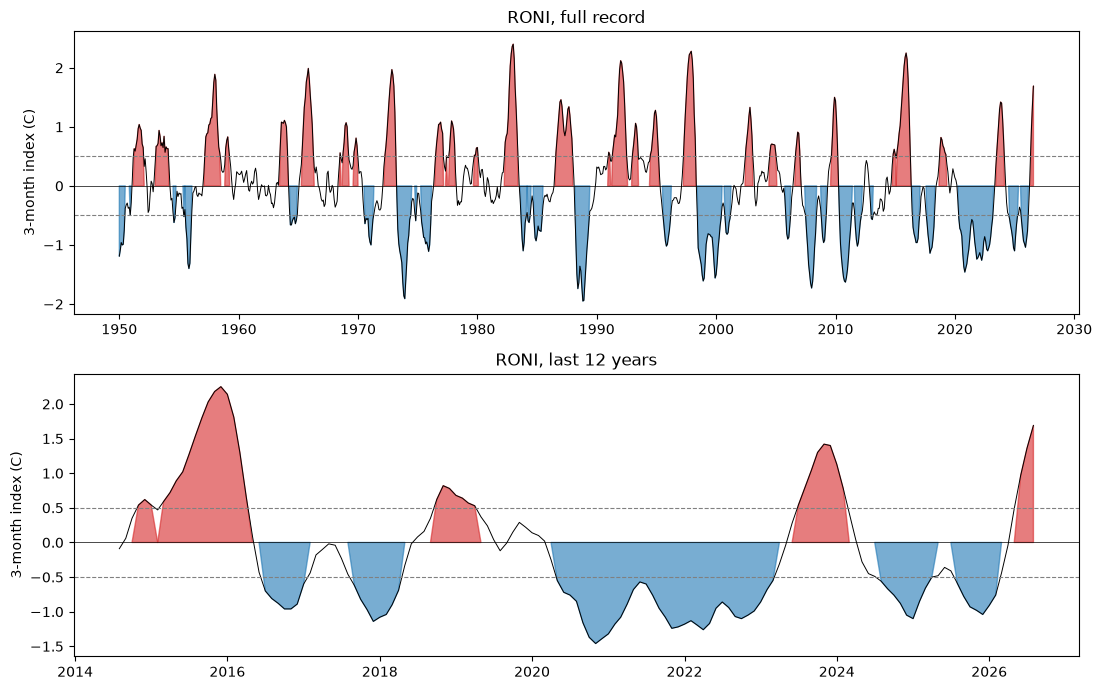

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7))
for ax, d, title in ((axes[0], enso, f"{INDEX}, full record"),
                     (axes[1], enso[enso["date"] >= enso["date"].max() - pd.DateOffset(years=12)], f"{INDEX}, last 12 years")):
    ax.fill_between(d["date"], 0, d["anom"], where=d["anom"] >= 0.5, color="tab:red", alpha=0.6, interpolate=True)
    ax.fill_between(d["date"], 0, d["anom"], where=d["anom"] <= -0.5, color="tab:blue", alpha=0.6, interpolate=True)
    ax.plot(d["date"], d["anom"], color="k", lw=0.7)
    ax.axhline(0.5, color="gray", ls="--", lw=0.8); ax.axhline(-0.5, color="gray", ls="--", lw=0.8)
    ax.axhline(0, color="k", lw=0.5)
    ax.set_ylabel("3-month index (C)"); ax.set_title(title)
plt.tight_layout(); plt.show()

## 2. Map ENSO onto water years

In [5]:
m = enso.copy()
m["year"], m["mon"] = m["date"].dt.year, m["date"].dt.month

def season_mean(frame, months, wy_offset, label):
    f = frame[frame["mon"].isin(months)].copy()
    f["wy"] = f["year"] + wy_offset
    g = f.groupby("wy")["anom"].agg(["mean", "count"])
    return g["mean"].where(g["count"] == len(months)).rename(label)   # require all seasons present

fall = season_mean(m, [10, 11, 12], 1, "fall_anom")     # SON, OND, NDJ  -> following water year
winter = season_mean(m, [1, 2, 3], 0, "winter_anom")    # DJF, JFM, FMA  -> same water year
wy_enso = pd.concat([fall, winter], axis=1).dropna(how="all")

def phase_of(x, thr=0.5):
    return pd.Series(np.where(x >= thr, "El Niño", np.where(x <= -thr, "La Niña", "Neutral")),
                     index=x.index).where(x.notna())

wy_enso["fall_phase"] = phase_of(wy_enso["fall_anom"])
wy_enso["winter_phase"] = phase_of(wy_enso["winter_anom"])
print(f"{wy_enso['winter_phase'].notna().sum()} water years with a winter ENSO value, "
      f"{wy_enso['fall_phase'].notna().sum()} with a fall value")
print(wy_enso["winter_phase"].value_counts().to_string())
wy_enso.round(2).tail(8)

77 water years with a winter ENSO value, 76 with a fall value
winter_phase
Neutral    31
El Niño    23
La Niña    23


,fall_anom,winter_anom,fall_phase,winter_phase
wy,,,,
2020,0.22,0.09,Neutral,Neutral
2021,-1.41,-1.19,La Niña,La Niña
2022,-1.18,-1.17,La Niña,La Niña
2023,-1.05,-0.70,La Niña,La Niña
2024,1.37,0.78,El Niño,El Niño
2025,-0.90,-0.87,La Niña,La Niña
2026,-0.98,-0.70,La Niña,La Niña
1950,NaN,-1.08,NaN,La Niña


## 3. ENSO vs. Colorado streamflow

Needs `data/co_streamflow_annual.csv`, written by the streamflow notebook (annual volume at the focus gauge). Samples are small (roughly 8-12 water years per phase) and Colorado's northern mountains sit in the transition zone between the wet-El-Niño southwest and dry-El-Niño northwest, so treat any relationship as suggestive and report the sample size and the permutation p-value alongside it.

36 complete water years with both streamflow (USGS-09239500) and ENSO values


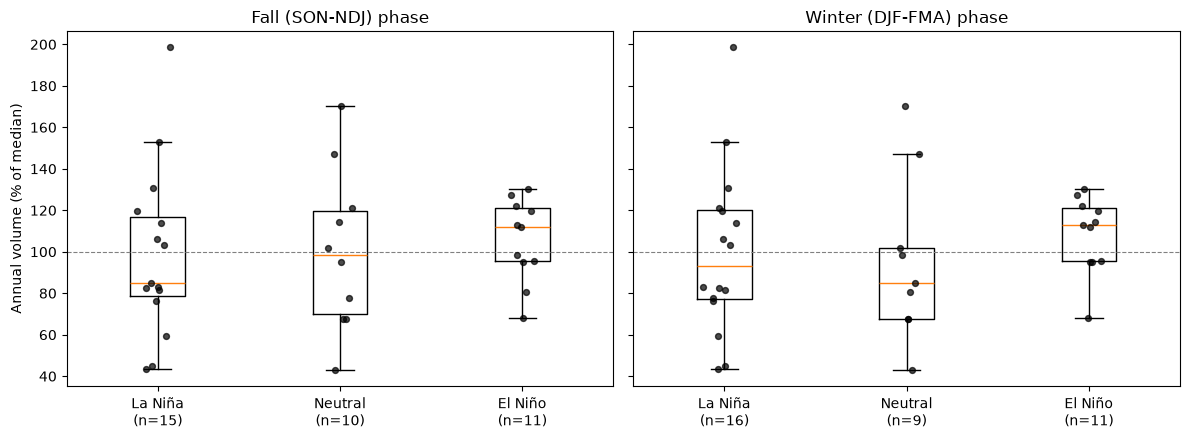

In [6]:
annual_path = DATA / "co_streamflow_annual.csv"
joined = None
if not annual_path.exists():
    print(f"{annual_path} not found. Run co_streamflow.ipynb first (it writes this file), then rerun this section.")
else:
    flow = pd.read_csv(annual_path)
    flow = flow[flow["complete"]].copy()
    flow["pct_of_median"] = flow["volume_acre_ft"] / flow["volume_acre_ft"].median() * 100
    joined = flow.merge(wy_enso, left_on="wy", right_index=True, how="inner")
    print(f"{len(joined)} complete water years with both streamflow ({flow['site'].iloc[0]}) and ENSO values")

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
    for ax, col, label in ((axes[0], "fall_phase", "Fall (SON-NDJ) phase"), (axes[1], "winter_phase", "Winter (DJF-FMA) phase")):
        order = ["La Niña", "Neutral", "El Niño"]
        groups = [joined.loc[joined[col] == p, "pct_of_median"].dropna() for p in order]
        ax.boxplot(groups, showfliers=False)
        ax.set_xticks(range(1, 4))
        ax.set_xticklabels([f"{p}\n(n={len(g)})" for p, g in zip(order, groups)])
        for k, g in enumerate(groups, start=1):
            ax.scatter(np.random.default_rng(0).normal(k, 0.05, len(g)), g, s=18, alpha=0.7, color="k", zorder=3)
        ax.axhline(100, color="gray", ls="--", lw=0.8)
        ax.set_title(label)
    axes[0].set_ylabel("Annual volume (% of median)")
    plt.tight_layout(); plt.show()

  predictor  spearman_r  perm_p  n
  fall_anom        0.02   0.905 36
winter_anom        0.04   0.799 36


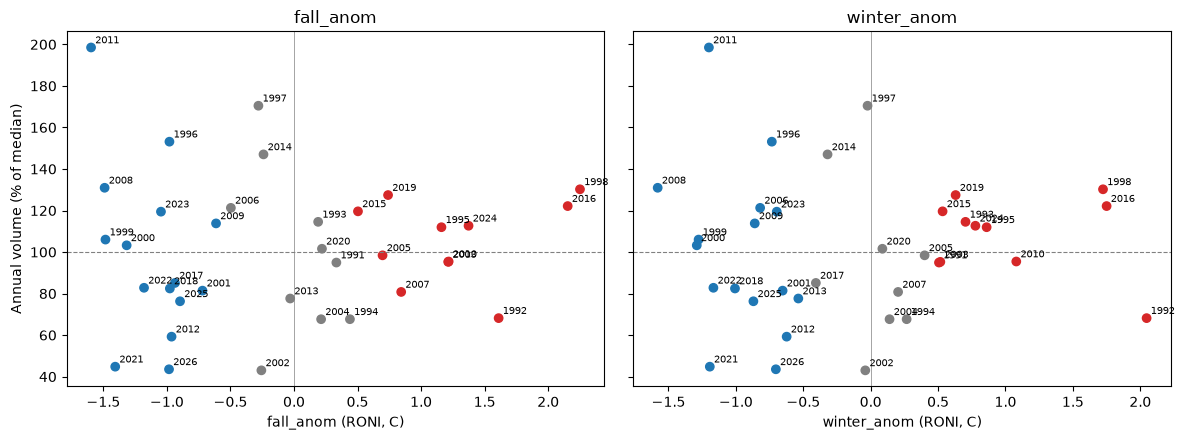

In [7]:
def rank_corr_perm(x, y, n_perm=5000, seed=0):
    """Spearman correlation (Pearson on ranks) with a two-sided permutation p-value."""
    ok = x.notna() & y.notna()
    rx, ry = x[ok].rank().values, y[ok].rank().values
    r = np.corrcoef(rx, ry)[0, 1]
    rng = np.random.default_rng(seed)
    hits = sum(abs(np.corrcoef(rx, rng.permutation(ry))[0, 1]) >= abs(r) for _ in range(n_perm))
    return r, (hits + 1) / (n_perm + 1), int(ok.sum())

if joined is not None and len(joined) >= 8:
    rows = []
    for col in ("fall_anom", "winter_anom"):
        r, p, n = rank_corr_perm(joined[col], joined["pct_of_median"])
        rows.append({"predictor": col, "spearman_r": round(r, 2), "perm_p": round(p, 3), "n": n})
    stats = pd.DataFrame(rows)
    print(stats.to_string(index=False))

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
    for ax, col in zip(axes, ("fall_anom", "winter_anom")):
        d = joined.dropna(subset=[col])
        ax.scatter(d[col], d["pct_of_median"], c=np.where(d[col] >= 0.5, "tab:red", np.where(d[col] <= -0.5, "tab:blue", "gray")))
        for _, r_ in d.iterrows():
            ax.annotate(str(int(r_["wy"])), (r_[col], r_["pct_of_median"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
        ax.axhline(100, color="gray", ls="--", lw=0.8); ax.axvline(0, color="gray", lw=0.5)
        ax.set_xlabel(f"{col} ({INDEX}, C)"); ax.set_title(col)
    axes[0].set_ylabel("Annual volume (% of median)")
    plt.tight_layout(); plt.show()
elif joined is not None:
    print("Too few overlapping years for a correlation.")

## 4. Dashboard snapshot

Writes `data/enso_monthly.csv` (the full classified series) and `data/enso_latest.json` (current status under both indices, plus the most recent events). A scheduled GitHub Action can rerun just this notebook's loading and snapshot cells; CPC updates the files monthly (around the second Thursday).

In [8]:
enso[["date", "seas", "yr", "anom", "phase"]].assign(index=INDEX).to_csv(DATA / "enso_monthly.csv", index=False)

snapshot = {"generated_utc": pd.Timestamp.now(tz="UTC").isoformat(timespec="seconds"), "index_used": INDEX, "indices": {}}
for n, d in indices.items():
    status, run = enso_status(d)
    last = d.iloc[-1]
    snapshot["indices"][n] = {"latest_season": f"{last['seas']} {int(last['yr'])}", "latest_anom": round(float(last["anom"]), 2),
                              "status": status, "consecutive_seasons_beyond_threshold": int(run)}
snapshot["recent_events"] = events.tail(6)[["phase", "span", "n_seasons", "peak", "strength"]].round(2).to_dict("records")
(DATA / "enso_latest.json").write_text(json.dumps(snapshot, indent=2, ensure_ascii=False), encoding="utf-8")
print("Wrote", DATA / "enso_monthly.csv", "and", DATA / "enso_latest.json")
print(json.dumps(snapshot["indices"], indent=2, ensure_ascii=False))

Wrote data\enso_monthly.csv and data\enso_latest.json
{
  "ONI": {
    "latest_season": "JAS 2026",
    "latest_anom": 2.16,
    "status": "El Niño developing: 4 of the 5 seasons needed to meet the CPC definition",
    "consecutive_seasons_beyond_threshold": 4
  },
  "RONI": {
    "latest_season": "JAS 2026",
    "latest_anom": 1.69,
    "status": "El Niño developing: 3 of the 5 seasons needed to meet the CPC definition",
    "consecutive_seasons_beyond_threshold": 3
  }
}
